# 3 – Tarea 1: Clasificación

**Objetivo:** Predecir la situación final del estudiante: `Abandono`, `Matriculado` o `Graduado`.

**Modelos probados:**
1. Regresión Logística 
2. Árbol de Decisión
3. Random Forest
4. Gradient Boosting

**Métricas:** Elegida porque el dataset está desbalanceado (~50% Graduado,  ~18% Matriculado) y queremos penalizar por igual los errores
  en todas las clases. La acompañamos con accuracy y la matriz de confusión


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle, warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix,f1_score, accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score, GridSearchCV

# Config figuras
plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')

# Cargamos datos preprocesados
X_train = np.load('datos_procesados/X_train_clf.npy')
X_test  = np.load('datos_procesados/X_test_clf.npy')
y_train = np.load('datos_procesados/y_train_clf.npy')
y_test  = np.load('datos_procesados/y_test_clf.npy')
X_train_s = np.load('datos_procesados/X_train_clf_scaled.npy')
X_test_s  = np.load('datos_procesados/X_test_clf_scaled.npy')

with open('datos_procesados/label_encoder_obj.pkl', 'rb') as f:
    le = pickle.load(f)

class_names = le.classes_
print("Clases:", class_names)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Clases: ['abandono' 'graduado' 'matriculado']
Train: (3539, 227), Test: (885, 227)


## 3.1 Regresión Logística

In [10]:
log_reg = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
log_reg.fit(X_train_s, y_train)
y_pred_log_reg = log_reg.predict(X_test_s)

print("o Regresión Logística: ")
print(classification_report(y_test, y_pred_log_reg, target_names=class_names))
f1_log_reg = f1_score(y_test, y_pred_log_reg, average='macro')
acc_log_reg = accuracy_score(y_test, y_pred_log_reg)
print(f"F1-macro: {f1_log_reg:.4f} | Accuracy: {acc_log_reg:.4f}")

o Regresión Logística: 
              precision    recall  f1-score   support

    abandono       0.79      0.70      0.74       284
    graduado       0.85      0.81      0.83       442
 matriculado       0.41      0.54      0.46       159

    accuracy                           0.73       885
   macro avg       0.68      0.69      0.68       885
weighted avg       0.75      0.73      0.74       885

F1-macro: 0.6802 | Accuracy: 0.7288


## 3.2 Árbol de Decisión

In [11]:
# Primero probamos sin mejorar
dt = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("o Árbol de Decisión (sin mejorar)")
print(f"F1-macro: {f1_score(y_test, y_pred_dt, average='macro'):.4f} \nAccuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(classification_report(y_test, y_pred_dt, target_names=class_names))
# Mejoramos con GridSearch
param_grid_dt = {
    'max_depth': [5, 10, 15, None],
    'min_samples_leaf': [1, 5, 10],
    'criterion': ['gini', 'entropy']
}
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=42, class_weight='balanced'),param_grid_dt, cv=5, scoring='f1_macro', n_jobs=-1)
gs_dt.fit(X_train, y_train)
dt_best = gs_dt.best_estimator_
y_pred_dt = dt_best.predict(X_test)

print(f"\no Árbol de Decisión (mejorado)")
print(f"Mejores parámetros: {gs_dt.best_params_}")
f1_dt = f1_score(y_test, y_pred_dt, average='macro')
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"F1-macro: {f1_dt:.4f} \nAccuracy: {acc_dt:.4f}")
print(classification_report(y_test, y_pred_dt, target_names=class_names))


o Árbol de Decisión (sin mejorar)
F1-macro: 0.6149 
Accuracy: 0.6836
              precision    recall  f1-score   support

    abandono       0.72      0.67      0.69       284
    graduado       0.79      0.81      0.80       442
 matriculado       0.35      0.36      0.36       159

    accuracy                           0.68       885
   macro avg       0.62      0.61      0.61       885
weighted avg       0.69      0.68      0.68       885


o Árbol de Decisión (mejorado)
Mejores parámetros: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1}
F1-macro: 0.6408 
Accuracy: 0.6859
              precision    recall  f1-score   support

    abandono       0.78      0.62      0.69       284
    graduado       0.81      0.78      0.80       442
 matriculado       0.36      0.53      0.43       159

    accuracy                           0.69       885
   macro avg       0.65      0.65      0.64       885
weighted avg       0.72      0.69      0.70       885



## 3.3 Random Forest

In [12]:
# Random Forest sin mejorar
rf = RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("o Random Forest (sin mejorar)")
print(f"F1-macro: {f1_score(y_test, y_pred_rf, average='macro'):.4f} \nAccuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(classification_report(y_test, y_pred_rf, target_names=class_names))
# Random Forest con GridSearch
param_grid_rf = {'n_estimators': [200,300],'max_depth': [10, 20, None],'min_samples_leaf': [1,3, 5]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),param_grid_rf, cv=5, scoring='f1_macro', n_jobs=-1)
gs_rf.fit(X_train, y_train)
rf_best = gs_rf.best_estimator_
y_pred_rf = rf_best.predict(X_test)

print("o Random Forest (mejorado)")
f1_rf = f1_score(y_test, y_pred_rf, average='macro')
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"F1-macro: {f1_rf:.4f} \nAccuracy: {acc_rf:.4f}")
print(f"Mejores parámetros: {gs_rf.best_params_}")
print(classification_report(y_test, y_pred_rf, target_names=class_names))



o Random Forest (sin mejorar)
F1-macro: 0.6886 
Accuracy: 0.7785
              precision    recall  f1-score   support

    abandono       0.82      0.76      0.79       284
    graduado       0.79      0.95      0.86       442
 matriculado       0.60      0.31      0.41       159

    accuracy                           0.78       885
   macro avg       0.74      0.68      0.69       885
weighted avg       0.76      0.78      0.76       885

o Random Forest (mejorado)
F1-macro: 0.7033 
Accuracy: 0.7627
Mejores parámetros: {'max_depth': 20, 'min_samples_leaf': 3, 'n_estimators': 300}
              precision    recall  f1-score   support

    abandono       0.83      0.71      0.77       284
    graduado       0.82      0.89      0.86       442
 matriculado       0.48      0.49      0.48       159

    accuracy                           0.76       885
   macro avg       0.71      0.70      0.70       885
weighted avg       0.76      0.76      0.76       885



## 3.4 Gradient Boosting

In [13]:
# Gradient Boosting
param_grid_gb = {'n_estimators': [100, 200],'max_depth': [3, 5],'learning_rate': [0.05, 0.1]}
gs_gb = GridSearchCV(GradientBoostingClassifier(random_state=42),param_grid_gb, cv=5, scoring='f1_macro', n_jobs=-1)
gs_gb.fit(X_train, y_train)
gb_best = gs_gb.best_estimator_
y_pred_gb = gb_best.predict(X_test)

print("o Gradient Boosting")
print(f"Mejores parámetros: {gs_gb.best_params_}")
print(classification_report(y_test, y_pred_gb, target_names=class_names))
f1_gb = f1_score(y_test, y_pred_gb, average='macro')
acc_gb = accuracy_score(y_test, y_pred_gb)
print(f"F1-macro: {f1_gb:.4f} | Accuracy: {acc_gb:.4f}")


o Gradient Boosting
Mejores parámetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
              precision    recall  f1-score   support

    abandono       0.82      0.73      0.77       284
    graduado       0.81      0.92      0.86       442
 matriculado       0.50      0.41      0.45       159

    accuracy                           0.77       885
   macro avg       0.71      0.69      0.69       885
weighted avg       0.76      0.77      0.76       885

F1-macro: 0.6945 | Accuracy: 0.7672


## 3.5 Comparativa de modelos

             Modelo  F1-macro (test)  Accuracy (test)
      Random Forest         0.703311         0.762712
  Gradient Boosting         0.694530         0.767232
Regresión Logística         0.680245         0.728814
  Árbol de Decisión         0.640760         0.685876


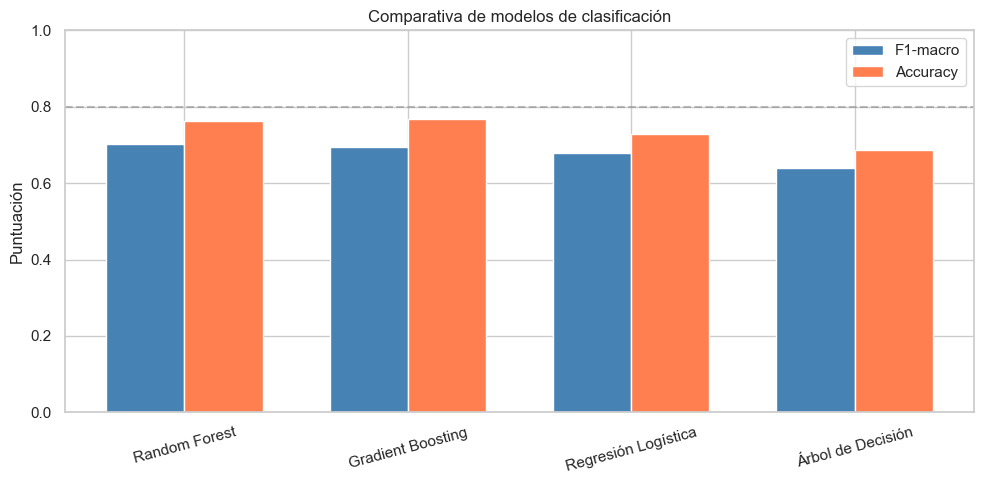

In [14]:
# Tabla resumen
resultados = pd.DataFrame({
    'Modelo': ['Regresión Logística', 'Árbol de Decisión', 'Random Forest', 'Gradient Boosting'],
    'F1-macro (test)': [f1_log_reg, f1_dt, f1_rf, f1_gb],
    'Accuracy (test)': [acc_log_reg, acc_dt, acc_rf, acc_gb]
}).sort_values('F1-macro (test)', ascending=False)

print(resultados.to_string(index=False))

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(resultados))
width = 0.35
ax.bar(x - width/2, resultados['F1-macro (test)'], width, label='F1-macro', color='steelblue')
ax.bar(x + width/2, resultados['Accuracy (test)'], width, label='Accuracy', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(resultados['Modelo'], rotation=15)
ax.set_ylim(0, 1)
ax.set_ylabel('Puntuación')
ax.set_title('Comparativa de modelos de clasificación')
ax.legend()
ax.axhline(0.8, color='gray', linestyle='--', alpha=0.5, label='Referencia 0.8')
plt.tight_layout()
plt.savefig('plots/comparativa_clasificacion.png', dpi=150, bbox_inches='tight')
plt.show()


## 3.6 Análisis del mejor modelo

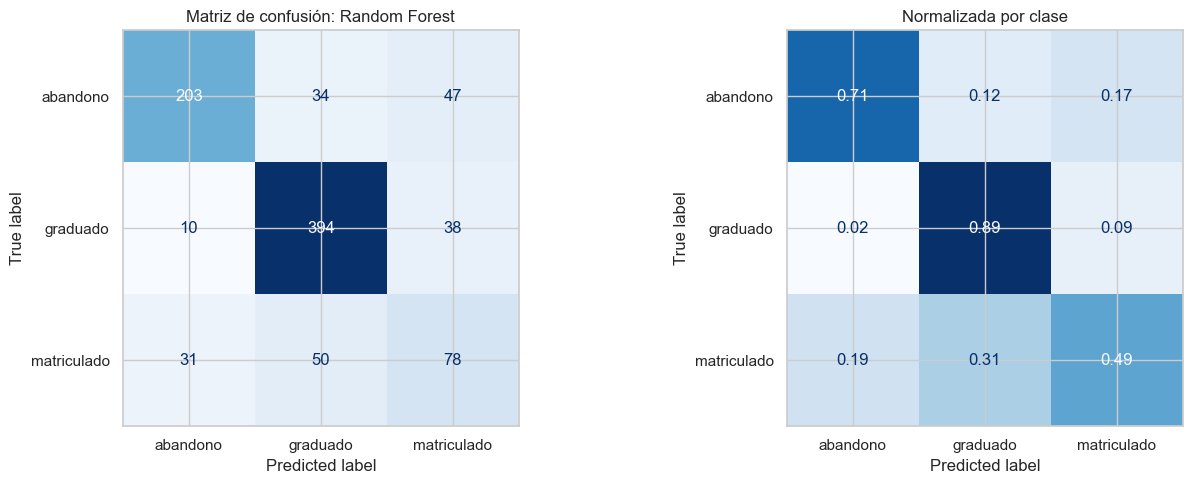

El modelo Random Forest confunde principalmente entre clases similares.


In [15]:
# Tomamos el mejor modelo
mejores_preds = {'log_reg': y_pred_log_reg, 'DT': y_pred_dt, 'RF': y_pred_rf, 'GB': y_pred_gb}
mejores_modelos = {'log_reg': log_reg, 'DT': dt_best, 'RF': rf_best, 'GB': gb_best}

mejor_nombre = resultados.iloc[0]['Modelo']
nombre_corto = {'Regresión Logística': 'log_reg', 'Árbol de Decisión': 'DT','Random Forest': 'RF', 'Gradient Boosting': 'GB'}[mejor_nombre]

y_pred_mejor = mejores_preds[nombre_corto]
modelo_mejor = mejores_modelos[nombre_corto]

# Matriz de confusión del mejor modelo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Valores absolutos
cm = confusion_matrix(y_test, y_pred_mejor)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Matriz de confusión: {mejor_nombre}')

# Normalizada
cm_norm = confusion_matrix(y_test, y_pred_mejor, normalize='true')
disp2 = ConfusionMatrixDisplay(cm_norm.round(2), display_labels=class_names)
disp2.plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title(f'Normalizada por clase')

plt.tight_layout()
plt.savefig('plots/confusion_matrix_mejor.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"El modelo {mejor_nombre} confunde principalmente entre clases similares.")


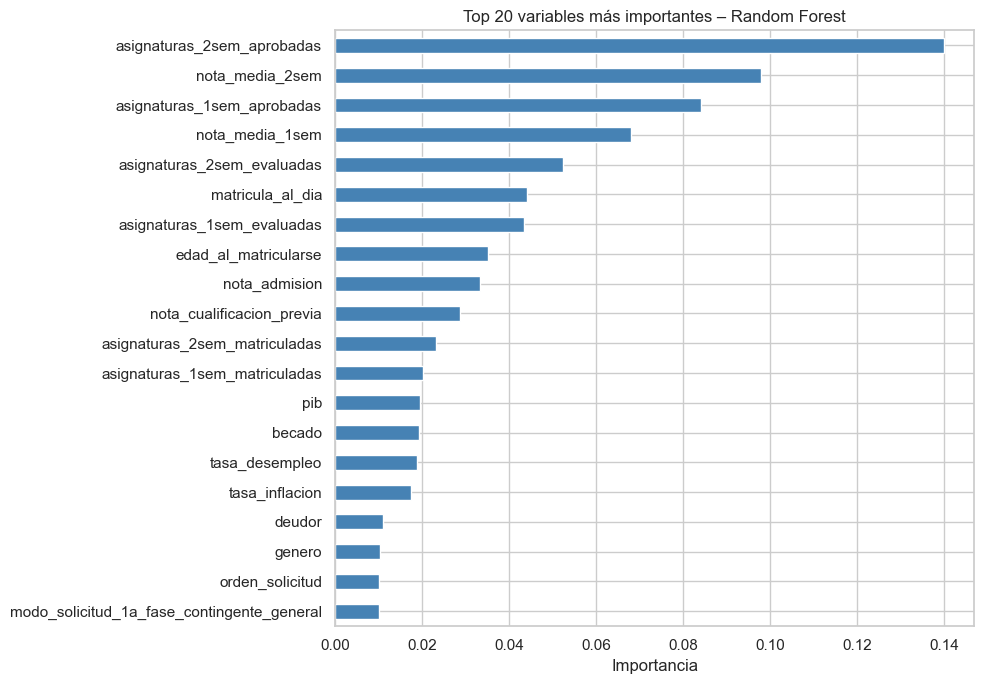

Las variables más importantes son:
  asignaturas_2sem_aprobadas: 0.1399
  nota_media_2sem: 0.0980
  asignaturas_1sem_aprobadas: 0.0840
  nota_media_1sem: 0.0680
  asignaturas_2sem_evaluadas: 0.0525


In [16]:
# Importancia de variables del mejor modelo (si es basado en árboles)
features_clf = pd.read_csv('datos_procesados/features_clf.csv').iloc[:, 0].tolist()
len(features_clf)

if hasattr(modelo_mejor, 'feature_importances_'):  # Si tiene atributo
    importances = pd.Series(modelo_mejor.feature_importances_, index=features_clf)
    top20 = importances.nlargest(20)
    
    plt.figure(figsize=(10, 7))
    top20.sort_values().plot(kind='barh', color='steelblue', edgecolor='white')
    plt.xlabel('Importancia')
    plt.title(f'Top 20 variables más importantes – {mejor_nombre}')
    plt.tight_layout()
    plt.savefig('plots/importancia_variables_clf.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("Las variables más importantes son:")
    for var, imp in top20.head(5).items():
        print(f"  {var}: {imp:.4f}")


## 3.7 Validación cruzada del mejor modelo

In [17]:
# Validación cruzada para asegurarnos de que no hay overfitting

cv_scores = cross_val_score(modelo_mejor, X_train, y_train,cv=5, scoring='f1_macro', n_jobs=-1)
gs_map = {'log_reg': None, 'DT': gs_dt, 'RF': gs_rf, 'GB': gs_gb}
gs_mejor = gs_map[nombre_corto]
if gs_mejor is not None:
    print(f"Mejor CV en GridSearch:  {gs_mejor.best_score_:.4f}")
print(f"F1-macro en test:        {f1_rf:.4f}")
print(f"CV F1-macro (5 folds): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Scores por fold: {cv_scores.round(4)}")


Mejor CV en GridSearch:  0.7196
F1-macro en test:        0.7033
CV F1-macro (5 folds): 0.7196 ± 0.0059
Scores por fold: [0.7149 0.7308 0.7191 0.7187 0.7144]


## 3.8 Conclusiones de Clasificación

- El mejor modelo es **Random Forest**, con F1-macro > 0.70 en test.
- La clase más difícil de predecir es **Matriculado**, ya que estos estudiantes pueden evolucionar hacia cualquiera de las otras dos clases.
- Las variables más relevantes son las del **rendimiento académico**: notas medias y asignaturas aprobadas en ambos semestres.
- Variables socioeconómicas como `matricula_al_dia` y `becado` también tienen peso relevante.
- El class_weight='balanced' mejora la predicción de la clase minoritaria (Matriculado).

**Limitación importante:** Las variables del 2do semestre introducen información "futura", por lo que este modelo no podría aplicarse al inicio del año para hacer predicciones preventivas. En un contexto real, habría que construir dos versiones: una con datos del 1er semestre únicamente.


In [18]:
for i, clase in enumerate(class_names):
    print(f"{clase}: {cm_norm[i,i]:.1%} correctamente clasificados")

abandono: 71.5% correctamente clasificados
graduado: 89.1% correctamente clasificados
matriculado: 49.1% correctamente clasificados
